In [1]:
import pandas as pd

# URL of the raw CSV file on GitHub
# Note: Replacing 'github.com' with 'raw.githubusercontent.com' and removing '/blob' to get the raw file content
csv_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/refs/heads/data-snapshots/data/live_snapshots/20261030_1324/skills.csv'

try:
    skills  = pd.read_csv(csv_url)
    print("DataFrame loaded successfully!")
except Exception as e:
    print(f"Error loading CSV directly: {e}")
    print("Attempting to load via requests...")
    import requests
    import io
    response = requests.get(csv_url)
    skills = pd.read_csv(io.StringIO(response.text))

DataFrame loaded successfully!


In [2]:
import pandas as pd

vacancies_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/refs/heads/data-snapshots/data/live_snapshots/20261030_1324/shown.csv'

try:
    vacancies = pd.read_csv(vacancies_url)
    print("Vacancies DataFrame loaded successfully!")
except Exception as e:
    import requests
    import io
    print(f"Error loading via pandas directly: {e}. Trying fallback with requests...")
    response = requests.get(vacancies_url)
    vacancies = pd.read_csv(io.StringIO(response.text))

# Join the two DataFrames on 'vacancy_id'
skills_flat = pd.merge(skills, vacancies, on='vacancy_id', how='inner')

print(f"Skills shape: {skills.shape}")
print(f"Vacancies shape: {vacancies.shape}")
print(f"Merged flat DataFrame shape: {skills_flat.shape}")
display(skills_flat.head())

Vacancies DataFrame loaded successfully!
Skills shape: (1512, 6)
Vacancies shape: (67, 29)
Merged flat DataFrame shape: (307, 34)


,run_id_x,vacancy_id,skill,strength,confidence,description_coverage_x,run_id_y,observation_id,source,source_id,...,description_coverage_y,collected_at,link,outcome,outcome_note,eligibility_reason,duplicate_of,duplicate_source,search_term,search_location
0,20261030T131438880602Z,reed:57250713,dashboards_reporting,unclear,stated,full,20261030T131438880602Z,obs-00006192,reed,57250713,...,full,2026-10-30T13:22:01+00:00,https://www.reed.co.uk/jobs/information-analys...,shown,NaN,NaN,NaN,NaN,data analyst,Shrewsbury
1,20261030T131438880602Z,reed:57250713,data_ethics_gdpr,unclear,stated,full,20261030T131438880602Z,obs-00006192,reed,57250713,...,full,2026-10-30T13:22:01+00:00,https://www.reed.co.uk/jobs/information-analys...,shown,NaN,NaN,NaN,NaN,data analyst,Shrewsbury
2,20261030T131438880602Z,reed:57250713,databases,essential,stated,full,20261030T131438880602Z,obs-00006192,reed,57250713,...,full,2026-10-30T13:22:01+00:00,https://www.reed.co.uk/jobs/information-analys...,shown,NaN,NaN,NaN,NaN,data analyst,Shrewsbury
3,20261030T131438880602Z,reed:57250713,sql,essential,stated,full,20261030T131438880602Z,obs-00006192,reed,57250713,...,full,2026-10-30T13:22:01+00:00,https://www.reed.co.uk/jobs/information-analys...,shown,NaN,NaN,NaN,NaN,data analyst,Shrewsbury
4,20261030T131438880602Z,reed:57382099,dashboards_reporting,essential,stated,full,20261030T131438880602Z,obs-00000006,reed,57382099,...,full,2026-10-30T13:20:51+00:00,https://www.reed.co.uk/jobs/data-analyst/57382099,shown,NaN,NaN,NaN,NaN,data analyst,Birmingham


In [3]:
# Display the first 5 rows and the dataframe's info
display(skills.head())
print("\nDataFrame Info:")
print("Shape:", skills.shape)
print("Columns:", skills.columns.tolist())
skills.info()
print(skills.isna().sum())

,run_id,vacancy_id,skill,strength,confidence,description_coverage
0,20261030T131438880602Z,greenhouse:gymshark-4863068101,crm_systems,desirable,stated,full
1,20261030T131438880602Z,greenhouse:gymshark-4958803101,excel,essential,stated,full
2,20261030T131438880602Z,greenhouse:gymshark-4959277101,data_analysis,essential,stated,full
3,20261030T131438880602Z,greenhouse:gymshark-4959277101,data_cleaning,unclear,stated,full
4,20261030T131438880602Z,greenhouse:gymshark-4959277101,erp_systems,desirable,stated,full



DataFrame Info:
Shape: (1512, 6)
Columns: ['run_id', 'vacancy_id', 'skill', 'strength', 'confidence', 'description_coverage']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1512 entries, 0 to 1511
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   run_id                1512 non-null   object
 1   vacancy_id            1512 non-null   object
 2   skill                 1512 non-null   object
 3   strength              1512 non-null   object
 4   confidence            1512 non-null   object
 5   description_coverage  1512 non-null   object
dtypes: object(6)
memory usage: 71.0+ KB
run_id                  0
vacancy_id              0
skill                   0
strength                0
confidence              0
description_coverage    0
dtype: int64


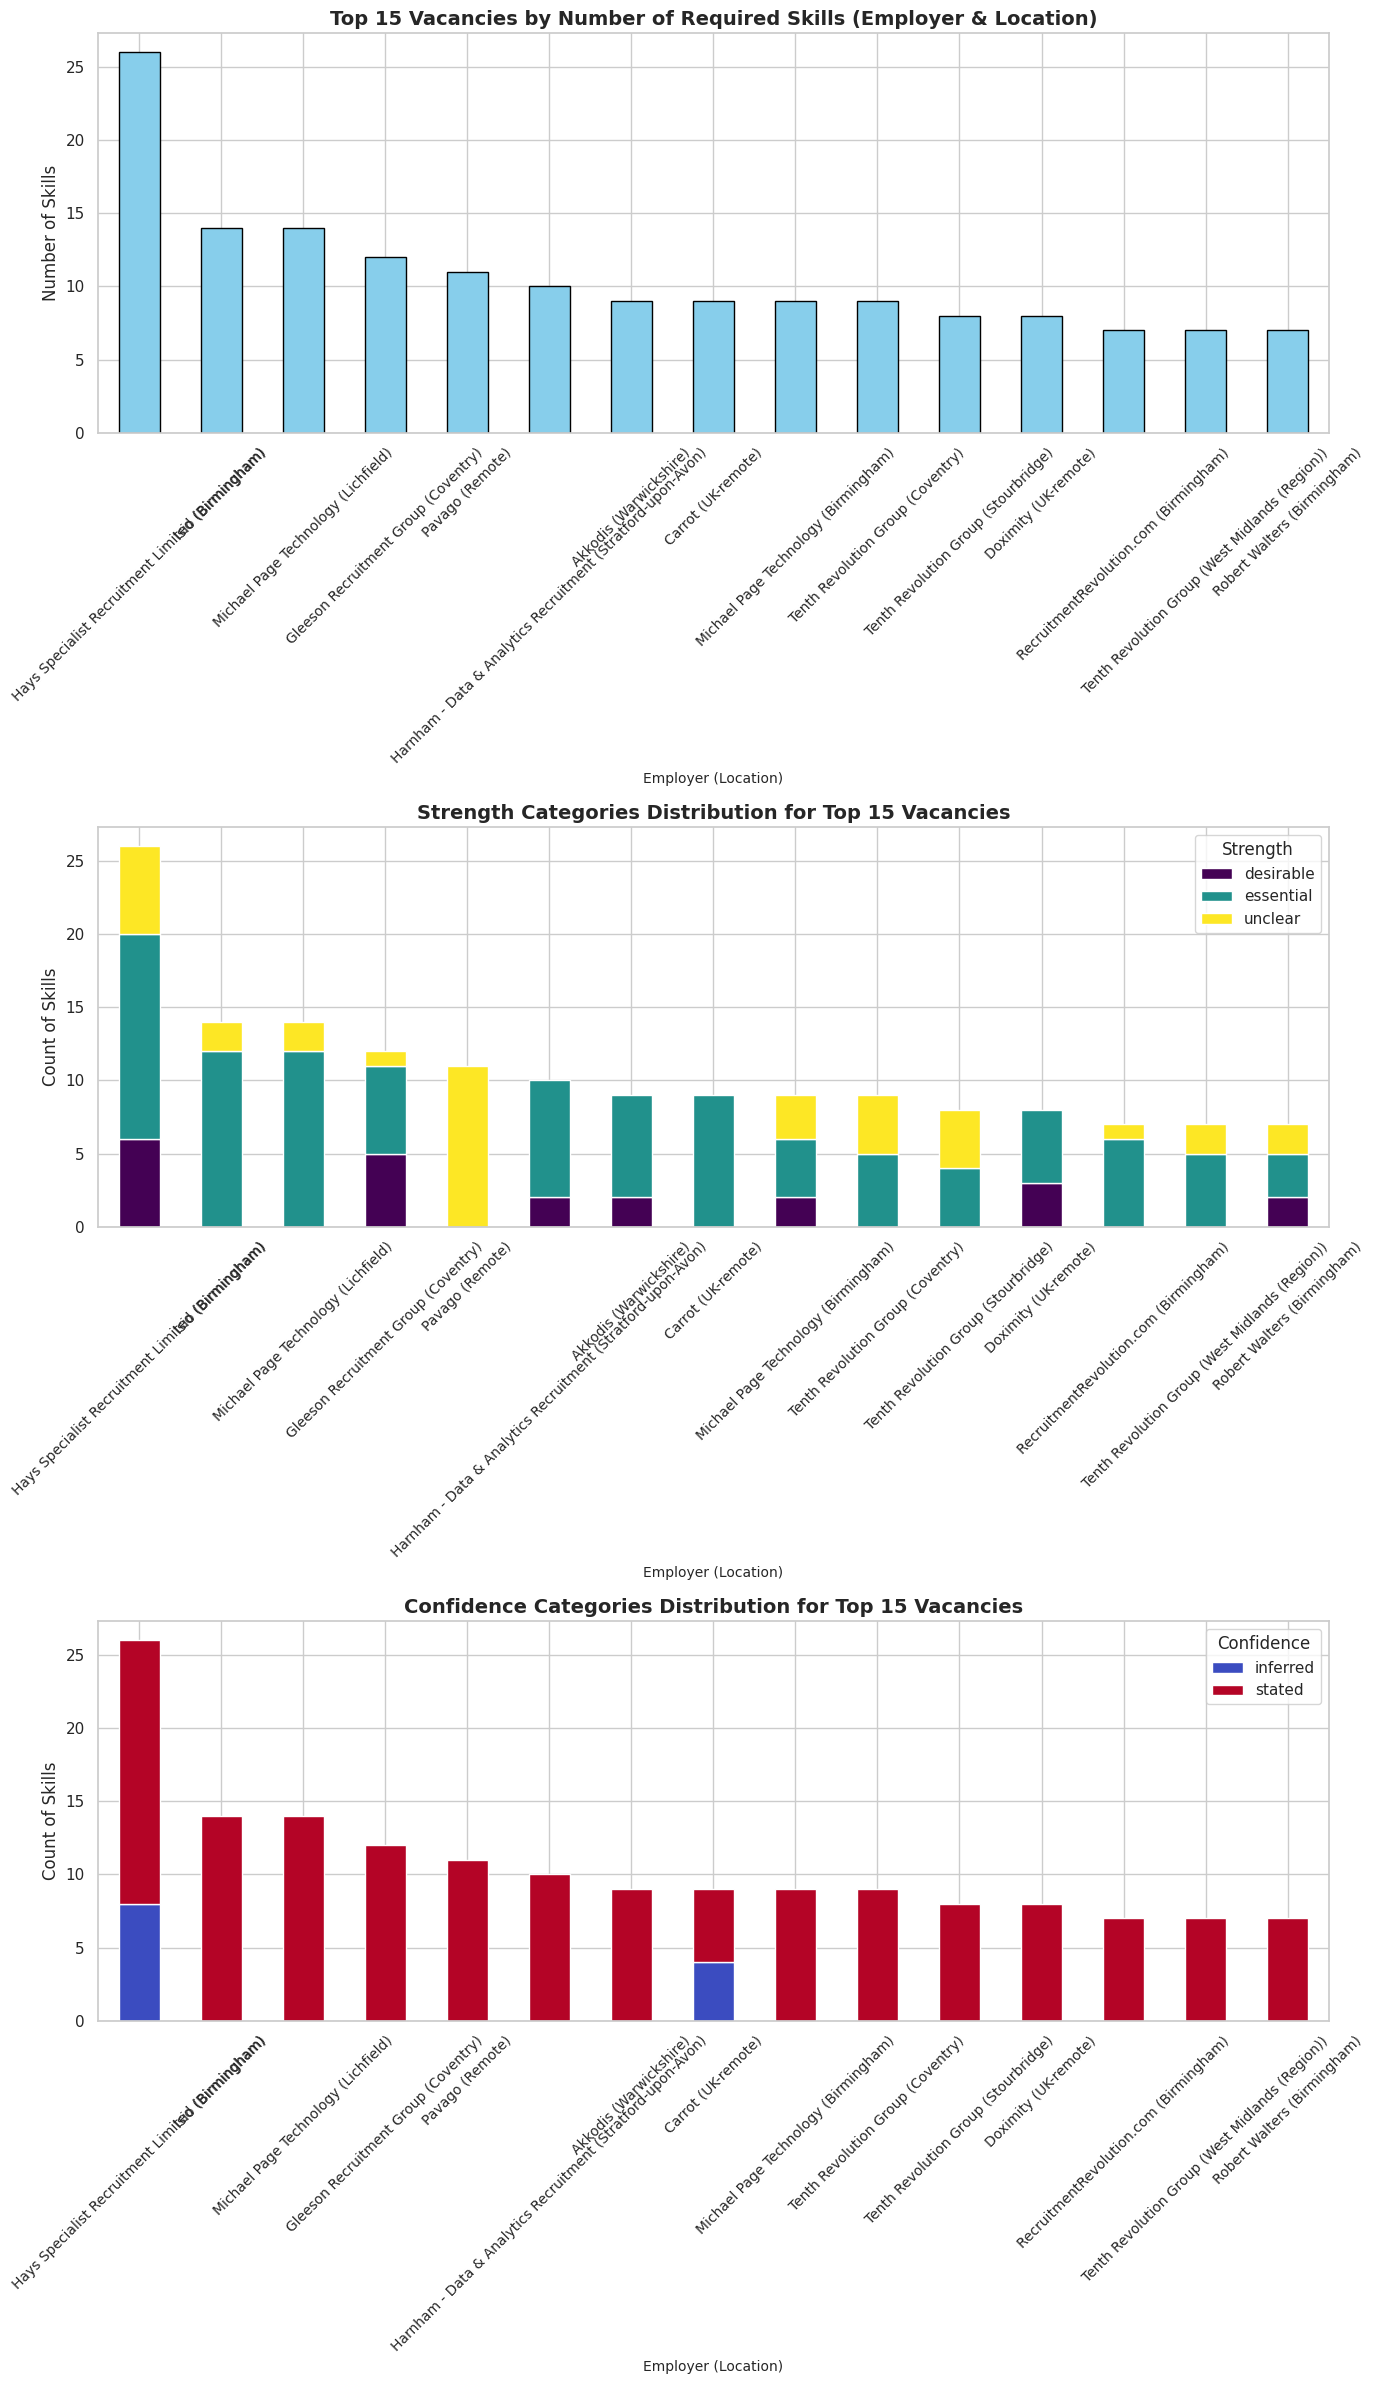

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set plotting style
sns.set_theme(style="whitegrid")

# Prepare readable identifier incorporating both Employer and Location
# Some records might have NaN values, so we handle them cleanly
skills_flat['employer_clean'] = skills_flat['employer'].fillna('Unknown Employer')
skills_flat['location_clean'] = skills_flat['location_text'].fillna('Unknown Location')
skills_flat['employer_location'] = skills_flat['employer_clean'] + ' (' + skills_flat['location_clean'] + ')'

# 1. Calculate basic aggregates per vacancy to identify the top 15
vacancy_skill_counts = skills_flat.groupby('employer_location')['skill'].count().sort_values(ascending=False)
top_vacancies_labels = vacancy_skill_counts.head(15).index

# Filter the flat dataframe to include only the top 15
skills_flat_top15 = skills_flat[skills_flat['employer_location'].isin(top_vacancies_labels)]

# 2. Prepare aggregated data for categorical columns 'strength' and 'confidence'
strength_by_vacancy = pd.crosstab(skills_flat_top15['employer_location'], skills_flat_top15['strength']).loc[top_vacancies_labels]
confidence_by_vacancy = pd.crosstab(skills_flat_top15['employer_location'], skills_flat_top15['confidence']).loc[top_vacancies_labels]

# Create a multi-plot figure
fig, axes = plt.subplots(3, 1, figsize=(14, 24))

# Plot 1: Number of skills per Employer / Location (Top 15)
vacancy_skill_counts.head(15).plot(kind='bar', ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title('Top 15 Vacancies by Number of Required Skills (Employer & Location)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Skills', fontsize=12)
axes[0].set_xlabel('Employer (Location)', fontsize=10)
axes[0].tick_params(axis='x', rotation=45, labelsize=10)

# Plot 2: Strength distribution per Employer / Location (Top 15)
strength_by_vacancy.plot(kind='bar', stacked=True, ax=axes[1], colormap='viridis')
axes[1].set_title('Strength Categories Distribution for Top 15 Vacancies', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Count of Skills', fontsize=12)
axes[1].set_xlabel('Employer (Location)', fontsize=10)
axes[1].tick_params(axis='x', rotation=45, labelsize=10)
axes[1].legend(title='Strength')

# Plot 3: Confidence distribution per Employer / Location (Top 15)
confidence_by_vacancy.plot(kind='bar', stacked=True, ax=axes[2], colormap='coolwarm')
axes[2].set_title('Confidence Categories Distribution for Top 15 Vacancies', fontsize=14, fontweight='bold')
axes[2].set_ylabel('Count of Skills', fontsize=12)
axes[2].set_xlabel('Employer (Location)', fontsize=10)
axes[2].tick_params(axis='x', rotation=45, labelsize=10)
axes[2].legend(title='Confidence')

plt.tight_layout()
plt.show()

The area of the shape represents the whole of the set of skills required. the red area show the skills not included in the course.   I am querying SQL because I don't think it was taught. “That SQL module was NOT IN (SELECT topic FROM .codeinstitute_LMS).”

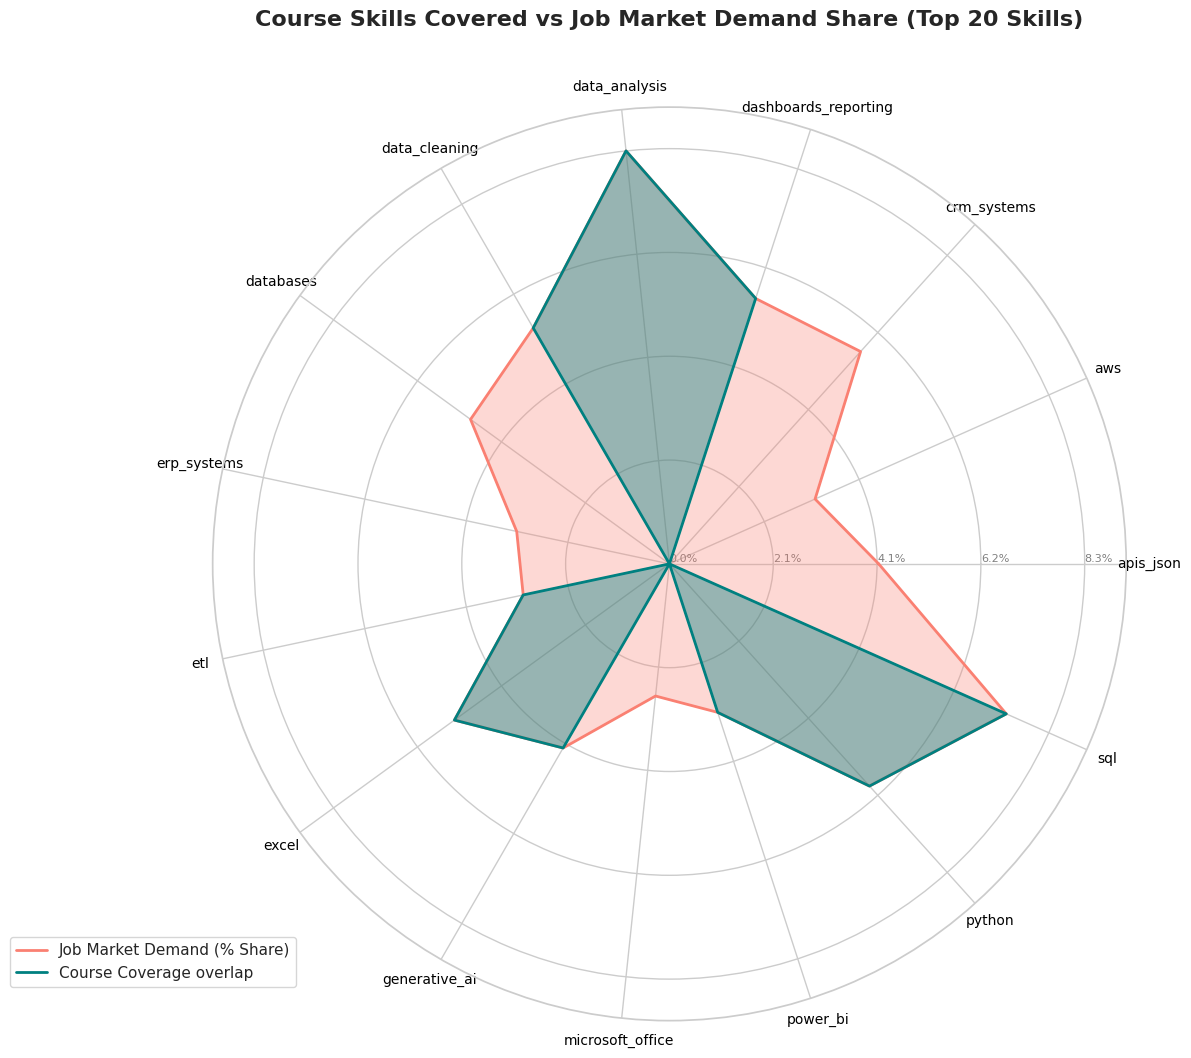

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import requests
import yaml

# URL of the raw CSV file on GitHub
# Note: Replacing 'github.com' with 'raw.githubusercontent.com' and removing '/blob' to get the raw file content
csv_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/refs/heads/data-snapshots/data/live_snapshots/20261030_1324/skills.csv'

skills  = pd.read_csv(csv_url)

# 1. Load the technical skills taxonomy to get course coverage (resolves NameError: df is not defined)
yaml_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/main/John%27s%20Folder/SkillMatch_App_Data/data/taxonomy/technical_skills.yaml'
try:
    response = requests.get(yaml_url)
    response.raise_for_status()
    taxonomy_data = yaml.safe_load(response.text)

    rows = []
    skills_list = taxonomy_data.get("skills", [])
    for item in skills_list:
        rows.append({
            "id": item.get("id"),
            "course_covered": item.get("course_covered", False)
        })
    df = pd.DataFrame(rows)
except Exception as e:
    print(f"Error fetching or parsing the YAML file: {e}")
    # Fallback to an empty DataFrame with required columns if download fails
    df = pd.DataFrame(columns=['id', 'course_covered'])

# 2. Calculate frequency of skills in the job market
skill_counts = skills['skill'].value_counts()
total_skills_demand = skill_counts.sum()

# Convert frequencies to relative percentages (demand share)
skill_percentages = (skill_counts / total_skills_demand) * 100

# Focus on the top 15 skills to keep the radar chart readable
top_n = 15
top_skills_list = list(skill_counts.head(top_n).index)
all_skills = sorted(top_skills_list)

# Filter df to check course coverage
covered_course_skills = set(df[df['course_covered'] == True]['id'])

# 3. Build radar chart values
# Job value represents the % demand frequency of the skill
job_values = [skill_percentages.get(skill, 0) for skill in all_skills]

# Course coverage value represents the same demand percentage IF covered, else 0
course_values = [skill_percentages.get(skill, 0) if skill in covered_course_skills else 0 for skill in all_skills]

# Number of variables
num_vars = len(all_skills)

# Compute angle for each axis
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

# Close the loop
course_values += course_values[:1]
job_values += job_values[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(12, 12), subplot_kw=dict(polar=True))

# Draw axes labels
plt.xticks(angles[:-1], all_skills, color='black', size=10, rotation=45)

# Set y-axis limits and labels representing sector percentages
ax.set_rlabel_position(0)
max_pct = max(job_values)
plt.yticks(np.linspace(0, max_pct, 5), [f"{val:.1f}%" for val in np.linspace(0, max_pct, 5)], color="grey", size=8)
plt.ylim(0, max_pct * 1.1)

# Plot Job Market (representing total demand percentage)
ax.plot(angles, job_values, linewidth=2, linestyle='solid', label="Job Market Demand (% Share)", color='salmon')
ax.fill(angles, job_values, color='salmon', alpha=0.3)

# Plot Course Skills Covered (representing covered share of that demand)
ax.plot(angles, course_values, linewidth=2, linestyle='solid', label="Course Coverage overlap", color='teal')
ax.fill(angles, course_values, color='teal', alpha=0.4)

# Details
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.title("Course Skills Covered vs Job Market Demand Share (Top 20 Skills)", size=16, fontweight='bold', y=1.08)

plt.tight_layout()
plt.show()

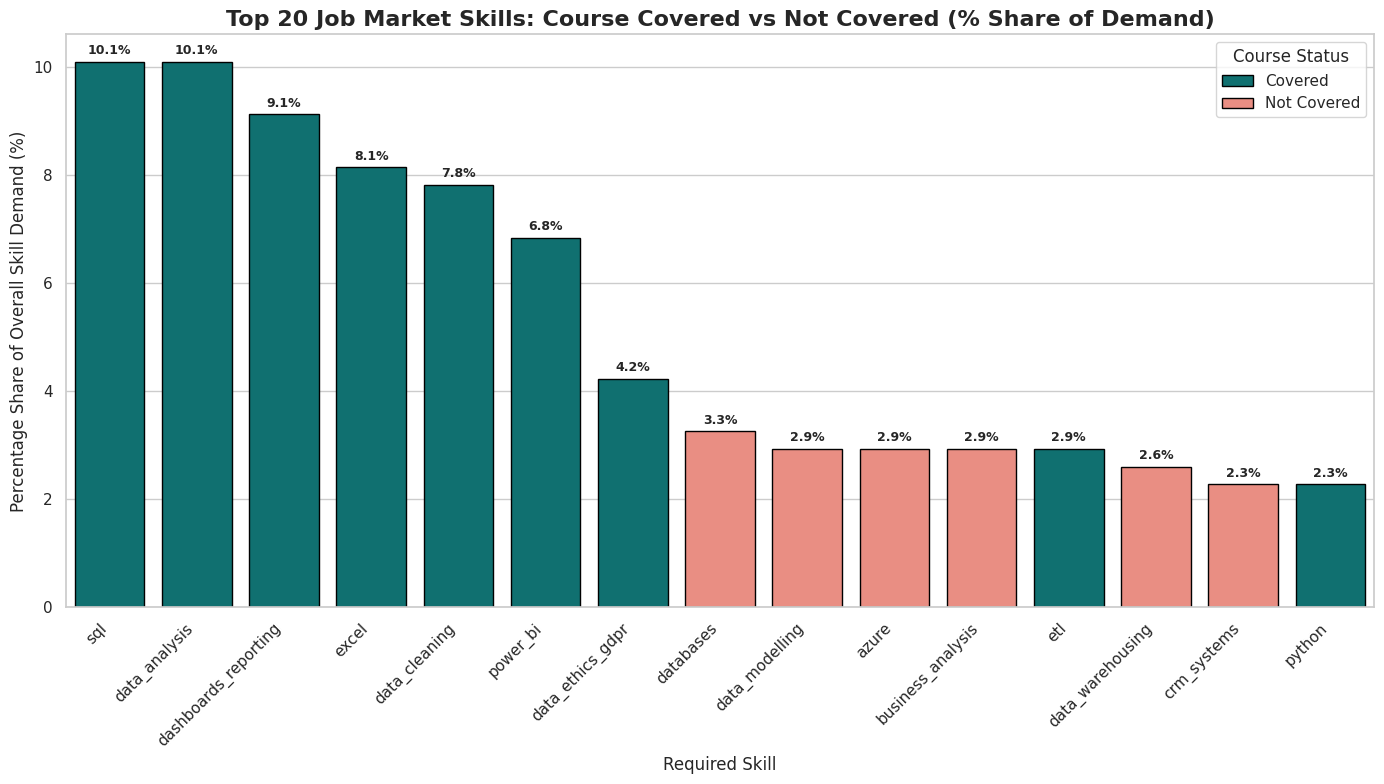

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Calculate frequency of skills in skills_flat
skill_counts = skills_flat['skill'].value_counts()
total_demand = skill_counts.sum()

# Convert to percentage share
skill_percentages = (skill_counts / total_demand) * 100

# Focus on the top 15 skills
top_n = 15
top_skills = skill_counts.head(top_n).index

# Filter taxonomy course coverage
covered_course_skills = set(df[df['course_covered'] == True]['id'])

# Build visualization dataset
plot_df = pd.DataFrame({
    'Skill': top_skills,
    'Percentage Share': [skill_percentages[skill] for skill in top_skills],
    'Course Covered': ['Covered' if skill in covered_course_skills else 'Not Covered' for skill in top_skills]
})

# Plot bar chart
plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=plot_df,
    x='Skill',
    y='Percentage Share',
    hue='Course Covered',
    palette={'Covered': 'teal', 'Not Covered': 'salmon'},
    edgecolor='black'
)

plt.title('Top 20 Job Market Skills: Course Covered vs Not Covered (% Share of Demand)', fontsize=16, fontweight='bold')
plt.xlabel('Required Skill', fontsize=12)
plt.ylabel('Percentage Share of Overall Skill Demand (%)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.legend(title='Course Status', fontsize=11, title_fontsize=12)

# Annotate percentages on top of bars
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.1f}%",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=9, fontweight='semibold')

plt.tight_layout()
plt.show()

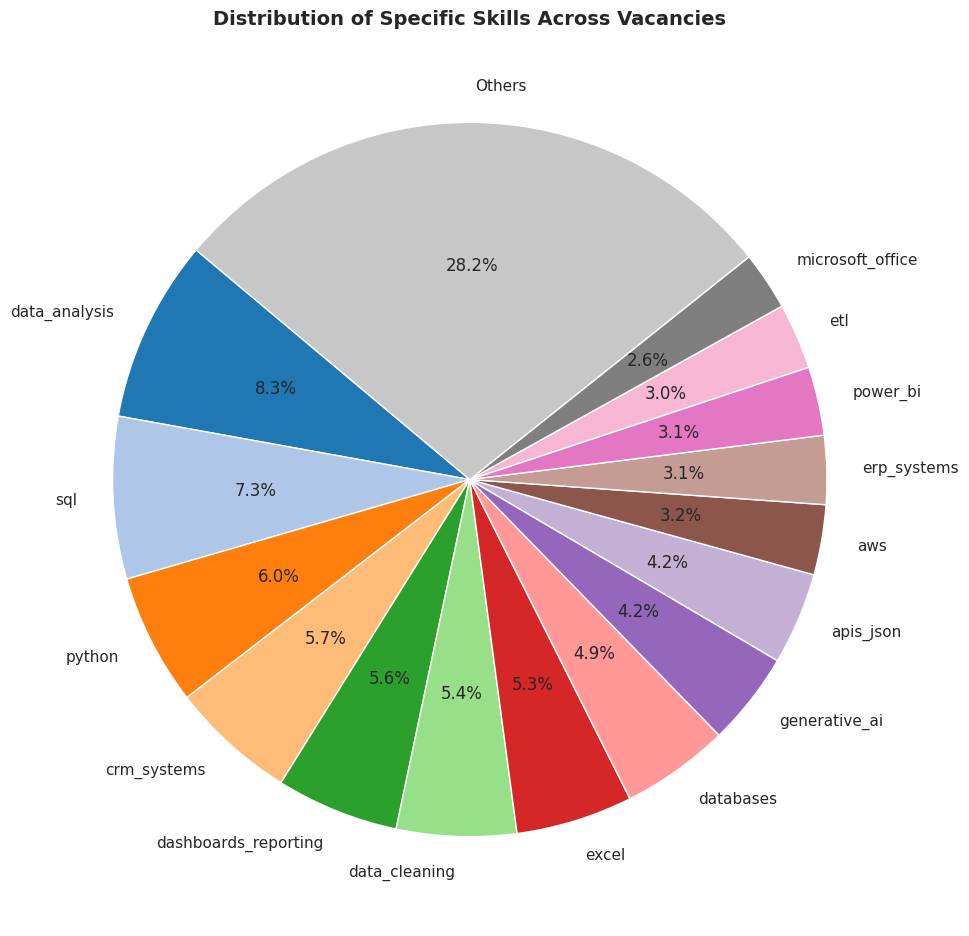

In [23]:
import matplotlib.pyplot as plt

# Count occurrences of each unique skill
skill_counts = skills['skill'].value_counts()

# To make the pie chart readable, we will show the top 10 skills and group the rest as 'Others'
top_n = 15
top_skills = skill_counts.head(top_n)
others_count = skill_counts.iloc[top_n:].sum()

# Combine top skills with 'Others'
plot_data = top_skills.copy()
if others_count > 0:
    plot_data['Others'] = others_count

# Create the pie chart
plt.figure(figsize=(10, 10))
plt.pie(
    plot_data,
    labels=plot_data.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=plt.cm.tab20.colors[:len(plot_data)]
)

plt.title('Distribution of Specific Skills Across Vacancies', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Loaded shown.csv successfully!


/tmp/ipykernel_981/698042601.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_locations.values, y=top_locations.index, ax=axes[0], palette="viridis")
/tmp/ipykernel_981/698042601.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_titles.values, y=top_titles.index, ax=axes[1], palette="magma")


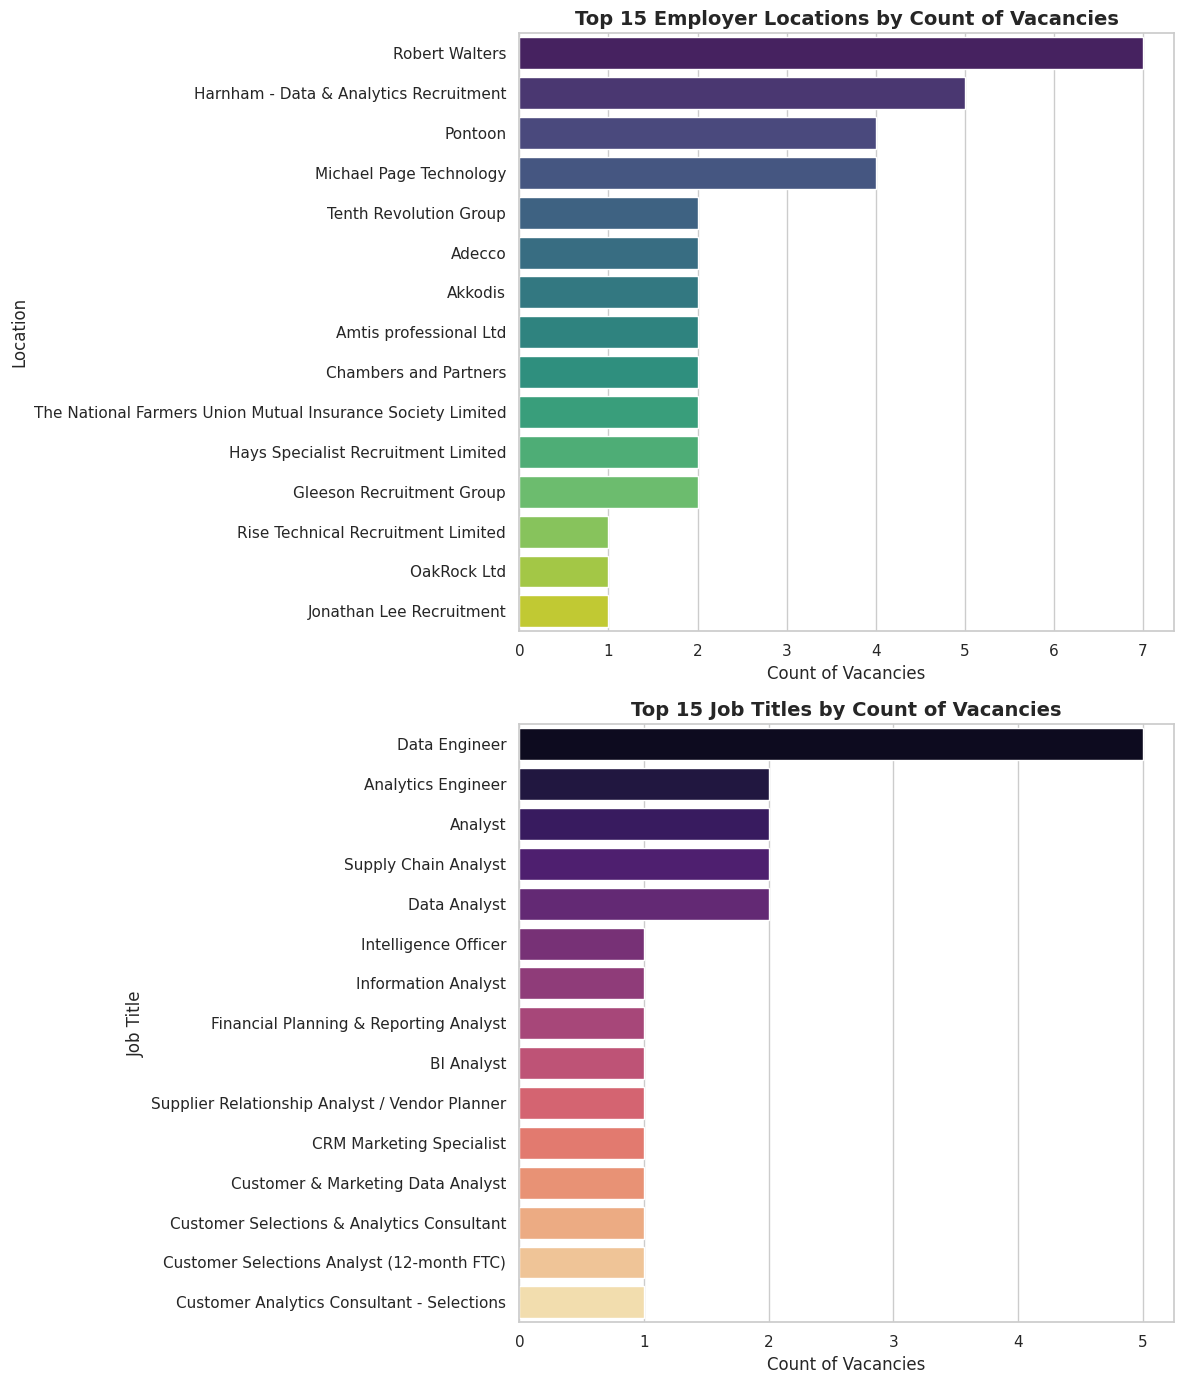

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert GitHub URL to Raw URL
shown_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/data-snapshots/data/live_snapshots/20261021_2033_reprocessed/shown.csv'

# Load the shown.csv dataset
try:
    shown_df = pd.read_csv(shown_url)
    print("Loaded shown.csv successfully!")
except Exception as e:
    import requests
    import io
    response = requests.get(shown_url)
    shown_df = pd.read_csv(io.StringIO(response.text))
    print("Loaded shown.csv via requests fallback.")

# Set seaborn theme
sns.set_theme(style="whitegrid")

# Set up matplotlib subplots
fig, axes = plt.subplots(2, 1, figsize=(12, 14))

# 1. Plot Employer Location counts
# Check the columns in the DataFrame to find exact matches for location and title
loc_col = [c for c in shown_df.columns if 'location' in c.lower() or 'employer' in c.lower()]
title_col = [c for c in shown_df.columns if 'title' in c.lower()]

# Use matched columns or fallback defaults
loc_column = loc_col[0] if loc_col else 'employer_text_location'
title_column = title_col[0] if title_col else 'title'

# Plot top employer locations
top_locations = shown_df[loc_column].value_counts().head(15)
sns.barplot(x=top_locations.values, y=top_locations.index, ax=axes[0], palette="viridis")
axes[0].set_title('Top 15 Employer Locations by Count of Vacancies', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Count of Vacancies', fontsize=12)
axes[0].set_ylabel('Location', fontsize=12)

# Plot top job titles
top_titles = shown_df[title_column].value_counts().head(15)
sns.barplot(x=top_titles.values, y=top_titles.index, ax=axes[1], palette="magma")
axes[1].set_title('Top 15 Job Titles by Count of Vacancies', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Count of Vacancies', fontsize=12)
axes[1].set_ylabel('Job Title', fontsize=12)

plt.tight_layout()
plt.show()

In [16]:
import requests
import yaml
import pandas as pd

# Convert GitHub blob URL to raw URL
yaml_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/refs/heads/data-snapshots/prototype/app/data/taxonomy/technical_skills.yaml'

try:
    response = requests.get(yaml_url)
    response.raise_for_status()
    data = yaml.safe_load(response.text)

    # Extract only the fields we want from the 'skills' key
    rows = []
    skills_list = data.get("skills", [])

    for item in skills_list:
        rows.append({
            "id": item.get("id"),
            "course_covered": item.get("course_covered")
        })

    df = pd.DataFrame(rows)
    display(df.head())
except Exception as e:
    print(f"Error fetching or parsing the YAML file: {e}")

,id,course_covered
0,python,True
1,pandas,True
2,numpy,True
3,r_language,False
4,vba,False


In [17]:
skills['skill'].head()

,skill
0,crm_systems
1,excel
2,data_analysis
3,data_cleaning
4,erp_systems


In [18]:
job_skills = set(skills['skill'].unique())
job_skills
skill_counts = skills['skill'].value_counts()
skill_counts

,count
skill,
data_analysis,125
sql,111
python,90
crm_systems,86
dashboards_reporting,84
data_cleaning,82
excel,80
databases,74
generative_ai,64


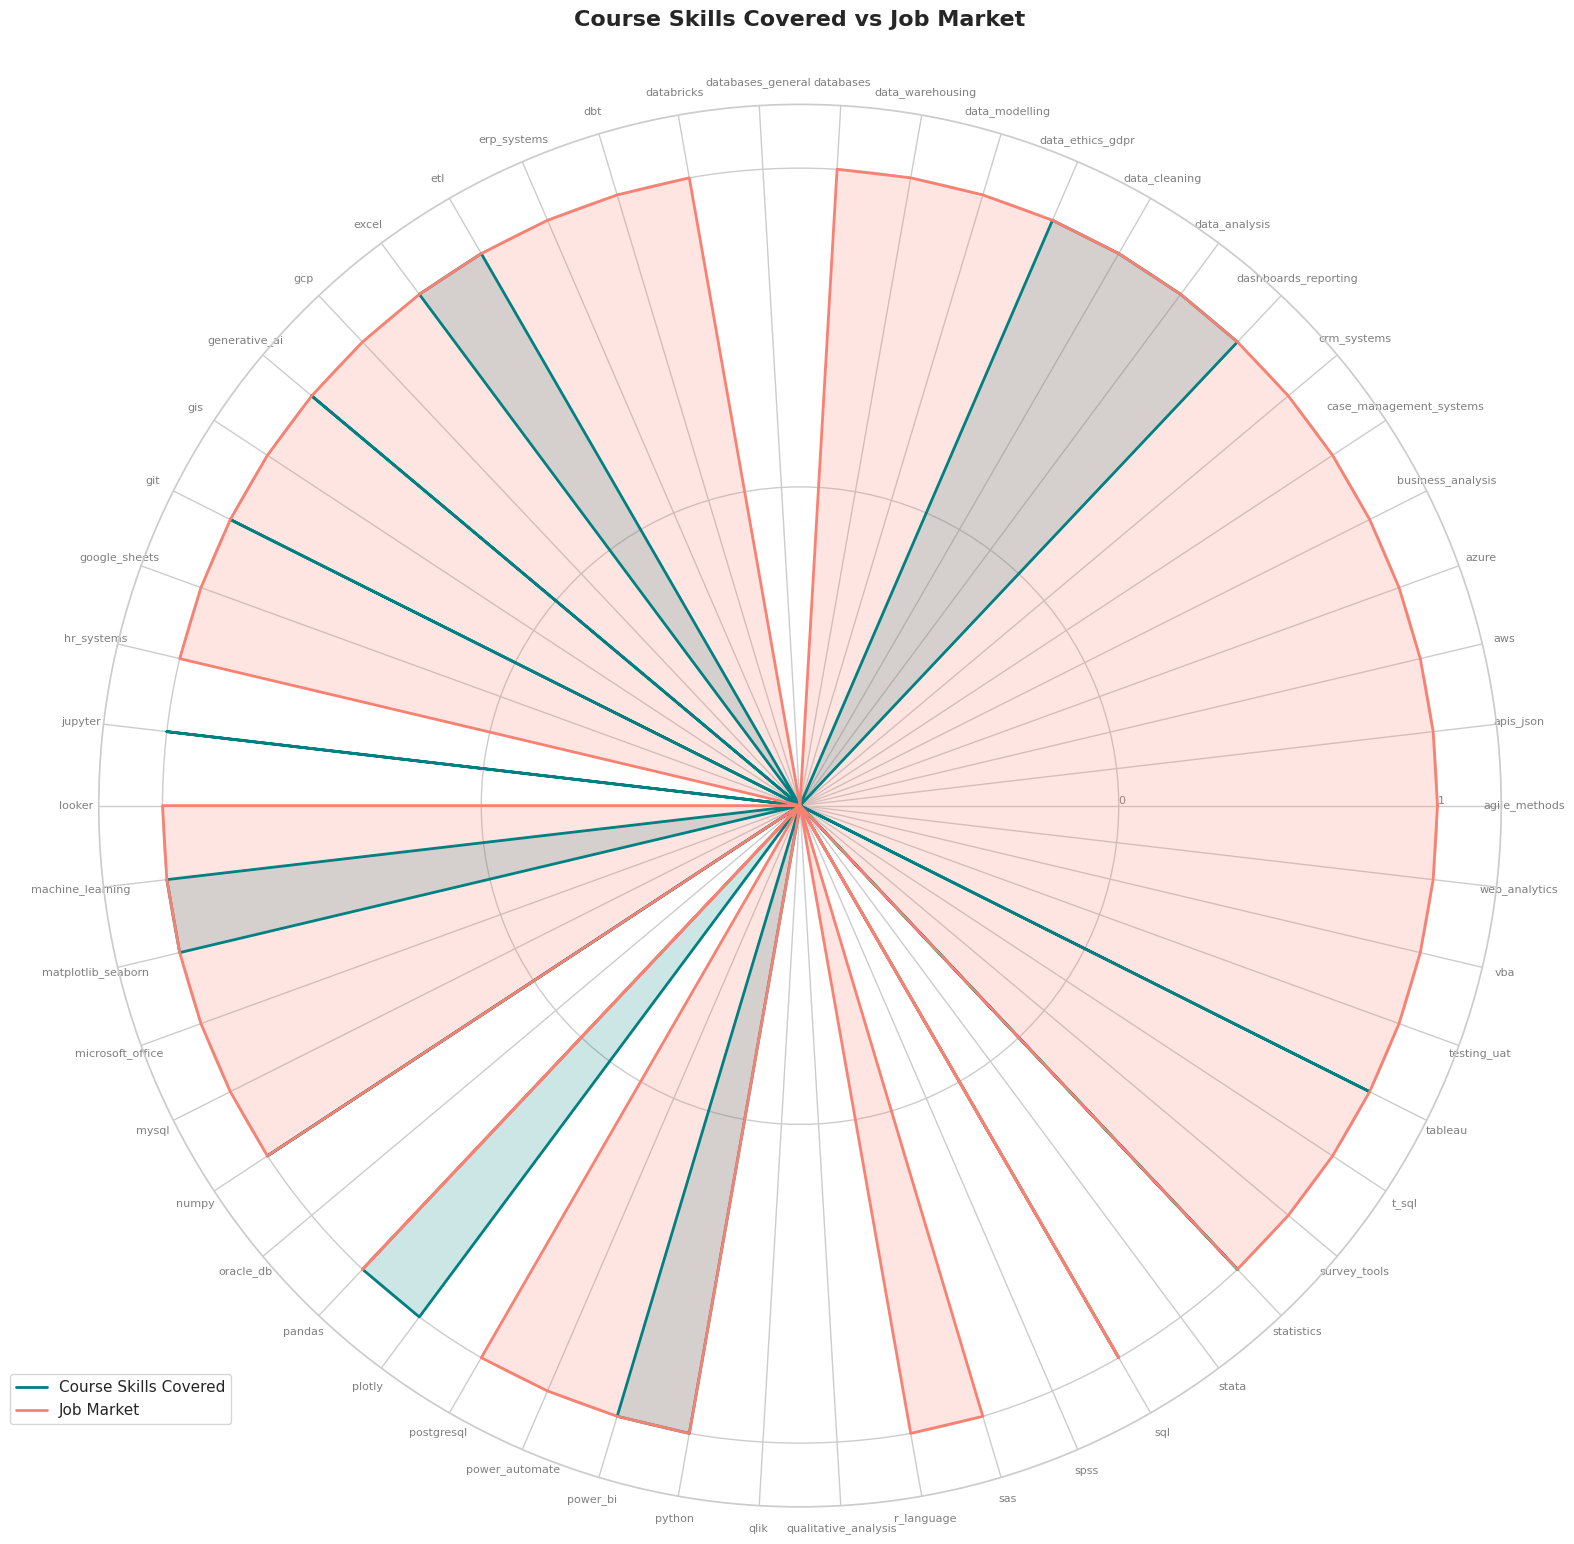

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Align skills
# Extract unique skills from both data sources
course_skills = set(df['id'].unique())
job_skills = set(skills['skill'].unique())

# Get the union of all skills
all_skills = sorted(list(course_skills.union(job_skills)))

# Filter df to quickly check coverage
covered_course_skills = set(df[df['course_covered'] == True]['id'])

# 2. Build radar chart data
course_values = [1 if skill in covered_course_skills else 0 for skill in all_skills]
job_values = [1 if skill in job_skills else 0 for skill in all_skills]

# 3. Plot radar chart
# Number of variables
num_vars = len(all_skills)

# Compute angle for each axis
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

# The radar chart needs to close the loop, so append the start value to the end
course_values += course_values[:1]
job_values += job_values[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(16, 16), subplot_kw=dict(polar=True))

# Draw one axe per variable and add labels
plt.xticks(angles[:-1], all_skills, color='grey', size=8, rotation=45)

# Draw ylabels
ax.set_rlabel_position(0)
plt.yticks([0.5, 1.0], ["0", "1"], color="grey", size=8)
plt.ylim(0, 1.1)

# Plot Course Skills Covered
ax.plot(angles, course_values, linewidth=2, linestyle='solid', label="Course Skills Covered", color='teal')
ax.fill(angles, course_values, color='teal', alpha=0.2)

# Plot Job Market
ax.plot(angles, job_values, linewidth=2, linestyle='solid', label="Job Market", color='salmon')
ax.fill(angles, job_values, color='salmon', alpha=0.2)

# Add Legend and Title
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.title("Course Skills Covered vs Job Market", size=16, fontweight='bold', y=1.05)

plt.tight_layout()
plt.show()

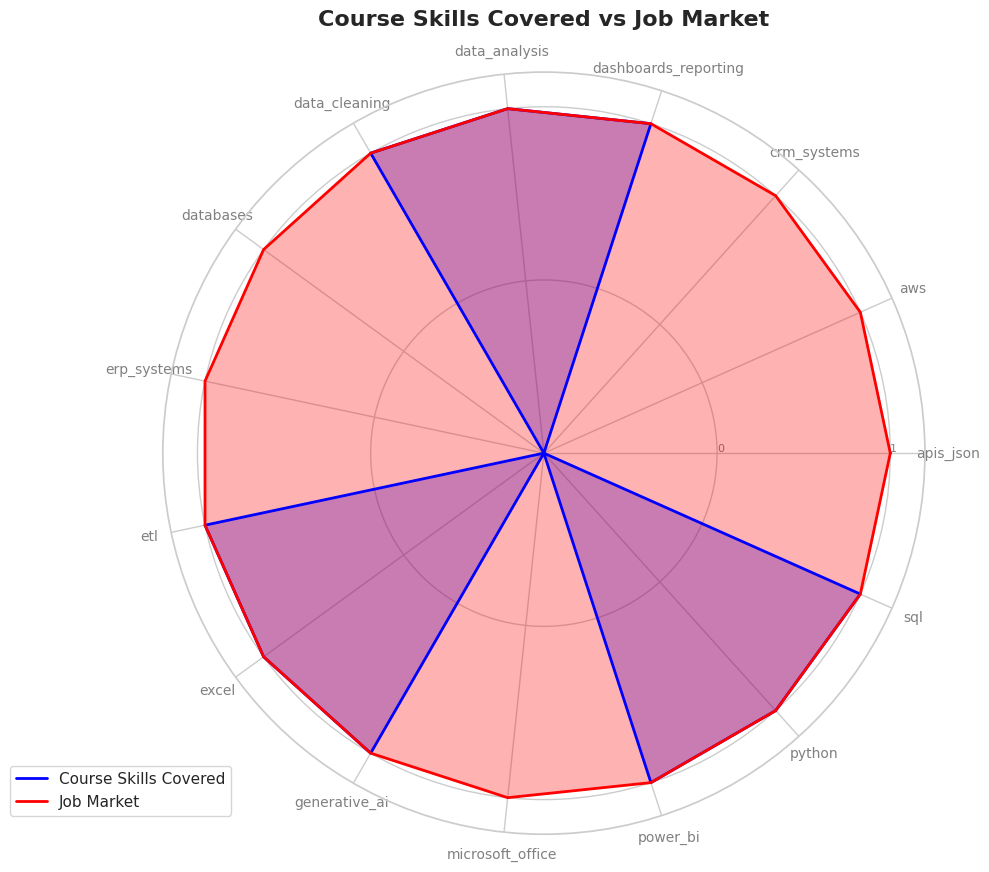

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Define top N limit for skills to keep the radar chart readable
top_n = 15

# Get top skills based on frequency in the job market
top_job_skills = list(skills['skill'].value_counts().head(top_n).index)

# Align skills focusing only on the top job market skills
all_skills = sorted(top_job_skills)

# Filter df to check course coverage
covered_course_skills = set(df[df['course_covered'] == True]['id'])

# Build radar chart data for these filtered skills
course_values = [1 if skill in covered_course_skills else 0 for skill in all_skills]
job_values = [1 if skill in top_job_skills else 0 for skill in all_skills]

# Number of variables
num_vars = len(all_skills)

# Compute angle for each axis
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

# Close the loop
course_values += course_values[:1]
job_values += job_values[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

# Draw axes
plt.xticks(angles[:-1], all_skills, color='grey', size=10, rotation=45)

# Draw y-axis labels
ax.set_rlabel_position(0)
plt.yticks([0.5, 1.0], ["0", "1"], color="grey", size=8)
plt.ylim(0, 1.1)

# Plot datasets
ax.plot(angles, course_values, linewidth=2, linestyle='solid', label="Course Skills Covered", color='blue')
ax.fill(angles, course_values, color='blue', alpha=0.3)

ax.plot(angles, job_values, linewidth=2, linestyle='solid', label="Job Market", color='red')
ax.fill(angles, job_values, color='red', alpha=0.3)

# Details
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.title("Course Skills Covered vs Job Market", size=16, fontweight='bold', y=1.05)

plt.tight_layout()
plt.show()

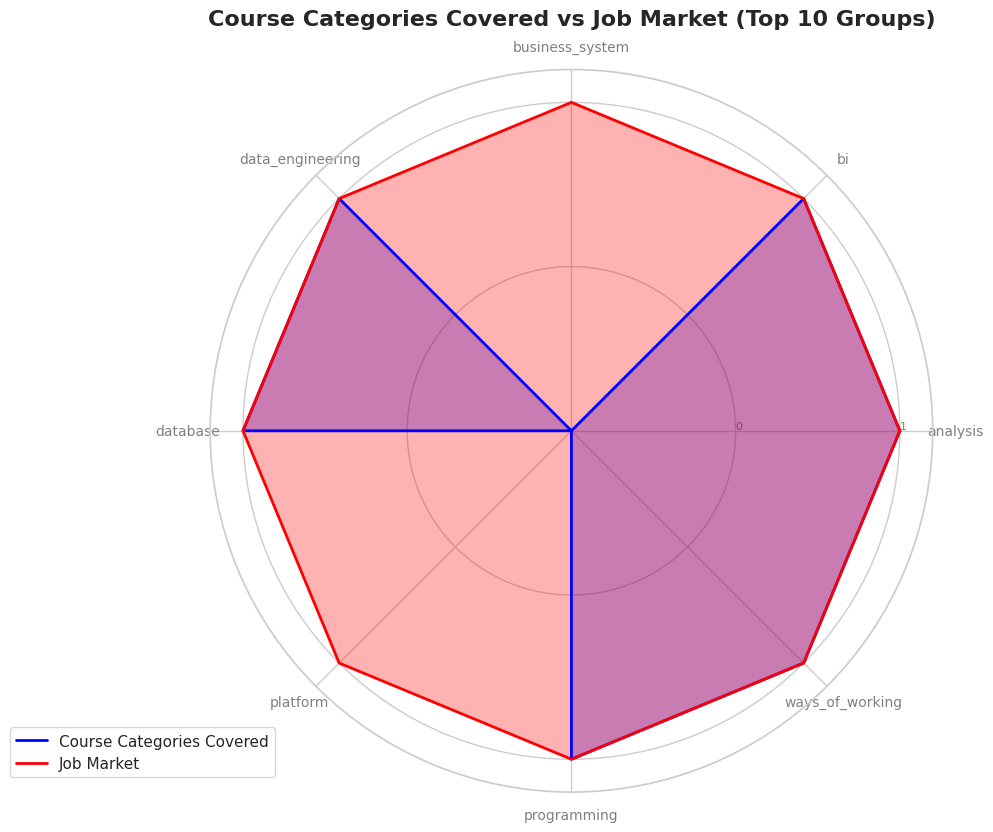

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 1. Map each skill 'id' to its 'category' from the original technical skills dataset
# Re-extract the category field from the YAML dataset first
rows_with_categories = []
skills_list = data.get("skills", [])
for item in skills_list:
    rows_with_categories.append({
        "id": item.get("id"),
        "category": item.get("category"),
        "course_covered": item.get("course_covered", False)
    })
category_df = pd.DataFrame(rows_with_categories)

# Create a dictionary for mapping skill id -> category
skill_to_cat = dict(zip(category_df['id'], category_df['category']))

# Map skills in our job market data to their categories
skills_mapped = skills.copy()
skills_mapped['category'] = skills_mapped['skill'].map(skill_to_cat)

# Drop rows where category is not found in taxonomy
skills_mapped = skills_mapped.dropna(subset=['category'])

# 2. Get the top 10 categories based on job market demand
top_n_categories = 8
top_cats = list(skills_mapped['category'].value_counts().head(top_n_categories).index)
all_categories = sorted(top_cats)

# 3. Calculate category coverage and demand
# - Course Category Covered: 1 if ANY skill in that category is covered in the course, else 0
covered_cats = set(category_df[category_df['course_covered'] == True]['category'])
course_values = [1 if cat in covered_cats else 0 for cat in all_categories]

# - Job Market Category: 1 if the category is present in the top job categories, else 0
job_values = [1 if cat in top_cats else 0 for cat in all_categories]

# 4. Plot radar chart
num_vars = len(all_categories)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

# Close the loop
course_values += course_values[:1]
job_values += job_values[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

# Draw axes labels
plt.xticks(angles[:-1], all_categories, color='grey', size=10, rotation=45)

# Draw y-axis labels
ax.set_rlabel_position(0)
plt.yticks([0.5, 1.0], ["0", "1"], color="grey", size=8)
plt.ylim(0, 1.1)

# Plot datasets
ax.plot(angles, course_values, linewidth=2, linestyle='solid', label="Course Categories Covered", color='blue')
ax.fill(angles, course_values, color='blue', alpha=0.3)

ax.plot(angles, job_values, linewidth=2, linestyle='solid', label="Job Market", color='red')
ax.fill(angles, job_values, color='red', alpha=0.3)

# Labels and Legend
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.title("Course Categories Covered vs Job Market (Top 10 Groups)", size=16, fontweight='bold', y=1.05)

plt.tight_layout()
plt.show()

In [29]:
import io
import pandas as pd
import requests
import yaml

# URLs from the workbook
csv_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/data-snapshots/data/live_snapshots/20261021_2033_reprocessed/skills.csv'
yaml_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/main/John%27s%20Folder/SkillMatch_App_Data/data/taxonomy/technical_skills.yaml'

# 1. Fresh load of the skills DataFrame
response_csv = requests.get(csv_url)
skills_fresh = pd.read_csv(io.StringIO(response_csv.text))

# 2. Get the top 25 skills and their counts
top_25_counts = skills_fresh['skill'].value_counts().head(25).reset_index()
top_25_counts.columns = ['skill', 'count']

# 3. Fresh load of the taxonomy to get course coverage
response_yaml = requests.get(yaml_url)
taxonomy_data = yaml.safe_load(response_yaml.text)

rows = []
for item in taxonomy_data.get("skills", []):
    rows.append({
        "skill": item.get("id"),
        "course_covered": item.get("course_covered", False)
    })
taxonomy_df = pd.DataFrame(rows)

# 4. Combine top 25 skills with course coverage
combined_df = pd.merge(top_25_counts, taxonomy_df, on='skill', how='left')

# Display the top rows
combined_df.head(25)

,skill,count,course_covered
0,data_analysis,93,True
1,sql,72,True
2,dashboards_reporting,70,True
3,excel,61,True
4,data_cleaning,55,True
5,power_bi,39,True
6,databases_general,38,False
7,python,36,True
8,crm_systems,33,False
9,microsoft_office,29,False


/tmp/ipykernel_981/3815279617.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


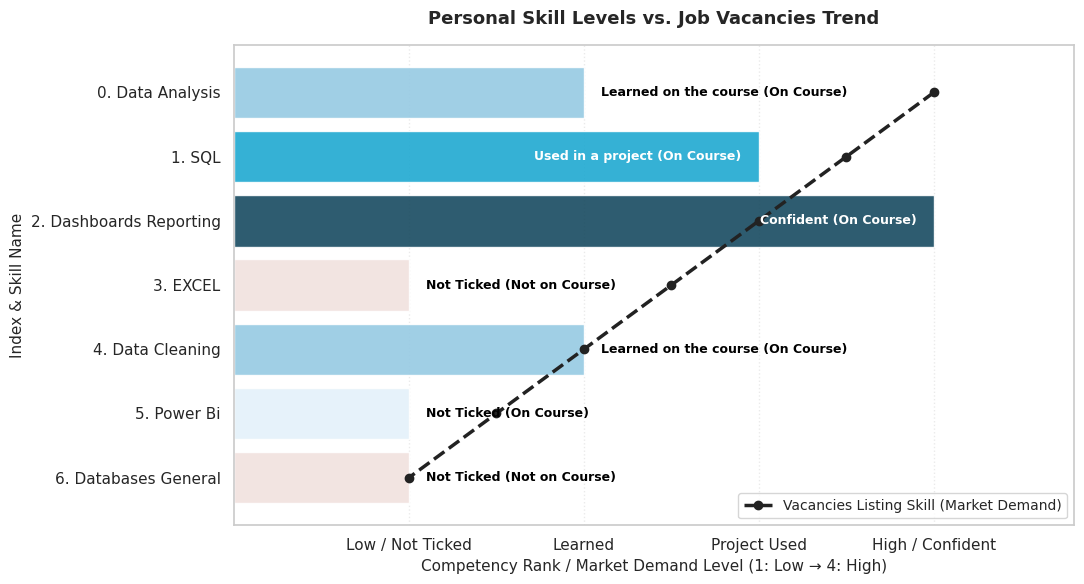

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Dataset setup
data = {
    'index': [0, 1, 2, 3, 4, 5, 6],
    'skill_id': ['data_analysis', 'sql', 'dashboards_reporting', 'excel', 'data_cleaning', 'power_bi', 'databases_general'],
    'skill': ['Data Analysis', 'SQL', 'Dashboards Reporting', 'EXCEL', 'Data Cleaning', 'Power Bi', 'Databases General'],
    'course_covered': [True, True, True, False, True, True, False],
    'level': ['Learned on the course', 'Used in a project', 'Confident', 'Not Ticked', 'Learned on the course', 'Not Ticked', 'Not Ticked']
}
df = pd.DataFrame(data)

# 2. Score mapping
level_weights = {
    'Confident': 4,
    'Used in a project': 3,
    'Learned on the course': 2,
    'Not Ticked': 1
}
df['score'] = df['level'].map(level_weights)
df['skill_label'] = df['index'].astype(str) + ". " + df['skill']

# 3. Dual-Palette Color Mapping
dual_palette_map = {
    (True, 'Confident'): '#0B4F6C',
    (True, 'Used in a project'): '#01BAEF',
    (True, 'Learned on the course'): '#89CFF0',
    (True, 'Not Ticked'): '#E0F2FE',
    (False, 'Confident'): '#A63A50',
    (False, 'Used in a project'): '#D65A31',
    (False, 'Learned on the course'): '#E8A87C',
    (False, 'Not Ticked'): '#F4E0DB'
}
df['bar_color'] = df.apply(lambda row: dual_palette_map[(row['course_covered'], row['level'])], axis=1)

# 4. Render Horizontal Bar Chart
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=df,
    x='score',
    y='skill_label',
    palette=df['bar_color'].tolist(),
    dodge=False,
    alpha=0.9
)

# 5. Dotted Line for Job Market Vacancy Trend
y_positions = np.arange(len(df))
max_index = len(df) - 1

# Curve/Line representing relative vacancy volume (Normalized 4 = Highest Vacancies, 1 = Lowest)
vacancy_trend = 4.0 - (3.0 * (y_positions / max_index))

ax.plot(
    vacancy_trend,
    y_positions,
    color='#222222',
    linestyle='--',
    linewidth=2.5,
    marker='o',
    markersize=6,
    label='Vacancies Listing Skill (Market Demand)'
)

# 6. Annotations inside bars
for p, level_text, covered in zip(ax.patches, df['level'], df['course_covered']):
    width = p.get_width()
    course_status = " (On Course)" if covered else " (Not on Course)"
    label = f"{level_text}{course_status}"

    text_color = 'white' if width > 2 else 'black'

    ax.text(
        width - 0.1 if width > 2 else width + 0.1,
        p.get_y() + p.get_height() / 2,
        label,
        va='center',
        ha='right' if width > 2 else 'left',
        color=text_color,
        fontweight='bold',
        fontsize=9
    )

# 7. Chart Titles and Legend
plt.title('Personal Skill Levels vs. Job Vacancies Trend', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Competency Rank / Market Demand Level (1: Low → 4: High)', fontsize=11)
plt.ylabel('Index & Skill Name', fontsize=11)
plt.xticks([1, 2, 3, 4], ['Low / Not Ticked', 'Learned', 'Project Used', 'High / Confident'])
plt.xlim(0, 4.8)
plt.grid(axis='x', linestyle=':', alpha=0.4)

plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()